# 06.02 ARTIFICIAL NEURAL NETWORKS - REGRESSION - EXERCISES (SOLUTIONS)

In [100]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

# reproducibility
np.random.seed(0)
tf.random.set_seed(0)

In [101]:
def plot_loss(history):
    plt.plot(history.history['loss'])
    if 'val_loss' in history.history:
        plt.plot(history.history['val_loss'])
        plt.legend(['Train', 'Val'], loc='upper left')
    plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.show()

## EXERCISE 1

In this exercise we will predict the house price, based on some house characteristics.

In [102]:
houses = fetch_california_housing()
houses_X = houses.data
houses_y = houses.target
print(houses.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

### 1. Data preparation

a. Print the shapes of houses_x and houses_y. How many houses do we have? How many featues do we have? Check whether there NaN values.

In [103]:
print('houses_X.shape:', houses_X.shape)
print('houses_y.shape:', houses_y.shape)

houses_X.shape: (20640, 8)
houses_y.shape: (20640,)


In [104]:
print('missing values in houses_X:', np.isnan(houses_X).sum())

missing values in houses_X: 0


b. Split the data in a train (90%) and test dataset (10%) (why do we do this?). Scale the train set using min_max scaling (why do we do this?). <strong>Important:</strong> We only fit scalers on training data and reuse the fitted scaler to scale test data.

In [105]:
houses_X_train, houses_X_test, houses_y_train, houses_y_test = train_test_split(
    houses_X, houses_y, test_size=0.10, random_state=0
)

In [106]:
# Scale features (fit on train only)
houses_scaler = MinMaxScaler()
houses_X_train_scaled = houses_scaler.fit_transform(houses_X_train)
houses_X_test_scaled = houses_scaler.transform(houses_X_test)

### 2. Define the model

Define the input layer with the right number of nodes. For the hidden layers, try out several options yourself. Define the output layer with the right number of nodes and a correct activation function. Print a model summary and compile the model with the Adam optimizer (choose the learning rate yourself), the correct loss function and a well choosen metric. How many parameters (weights and biases) does your model have?

In [107]:
n_features_houses = houses_X.shape[1]

# input layer 784 nodes
inputs = Input(shape=(n_features_houses,))
# 2 hidden layer
x = Dense(128, activation='relu')(inputs)
x = Dense(64, activation='relu')(x)
# output layer
outputs = Dense(1, activation='linear')(x)
# construct the model
houses_model = Model(inputs, outputs, name='HOUSE')
# compile the model
houses_model.compile(optimizer=Adam(learning_rate=1e-3),
                     loss='mean_squared_error',
                     metrics=['mean_absolute_percentage_error'])
# print a summary
houses_model.summary()

Model: "HOUSE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,473 (37.00 KB)

 Trainable params: 9,473 (37.00 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Train the model

Train the model with 10% of the training data taken for validation. Choose the number of epochs and the batch_size. Plot the loss function. Do we have overfitting?

Epoch 1/50
523/523 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.8274 - mean_absolute_percentage_error: 40.6445 - val_loss: 0.5369 - val_mean_absolute_percentage_error: 31.3415
Epoch 2/50
523/523 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5467 - mean_absolute_percentage_error: 31.2747 - val_loss: 0.4790 - val_mean_absolute_percentage_error: 28.4403
Epoch 3/50
523/523 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5001 - mean_absolute_percentage_error: 29.0633 - val_loss: 0.4349 - val_mean_absolute_percentage_error: 27.8648
Epoch 4/50
523/523 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4662 - mean_absolute_percentage_error: 27.3875 - val_loss: 0.4155 - val_mean_absolute_percentage_error: 28.1613
Epoch 5/50
523/523 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4452 - mean_absolute_percentage_error: 26.3846 - val_loss: 0.4041 - val_mean_absolute_percentage_error: 28.1383
Epoch 6/50
523/523 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4301 - mean_absolute_percentage_error: 25.7130 - val_loss: 0.3963 - 

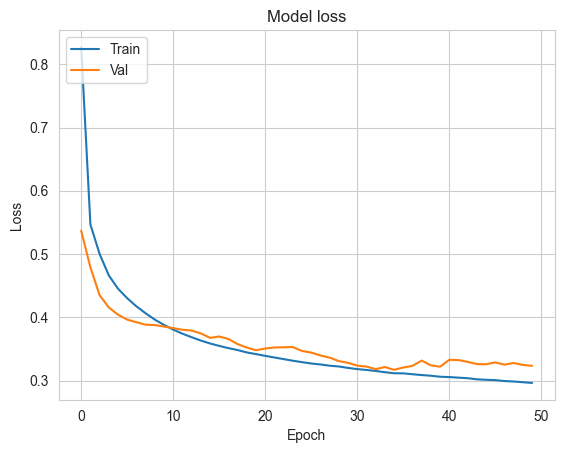

In [108]:

# train the model
history_houses = houses_model.fit(
    houses_X_train_scaled,  # Train features (scaled)
    houses_y_train,  # Train target (the house price)
    epochs=50,
    batch_size=32,
    validation_split=0.1,
)
# plot loss function
plot_loss(history_houses)

### 4. Evaluate the model

Evaluate the model with the test dataset (why thisone?). What is the accuracy of the model?

In [109]:
eval_houses = houses_model.evaluate(houses_X_test_scaled, houses_y_test)
print('Houses test MSE, MAPE:', eval_houses)

65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3331 - mean_absolute_percentage_error: 24.6434
Houses test MSE, MAPE: [0.3330715596675873, 24.6434326171875]


### 5. Use the model to predict

There is a house on the market with the following values for the features: 3,30,5,1,1500,4,38,-125. Predict the price for this housee. What should be the shape of the predict parameter? Can we feed in the feature values right away? 

In [110]:
new_house = np.array([[3, 30, 5, 1, 1500, 4, 38, -125]])
new_house_scaled = houses_scaler.transform(new_house)
predicted_price = houses_model.predict(new_house_scaled)
print('Predicted house price:', float(predicted_price[0, 0]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Predicted house price: 7.185577392578125
